In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
import shapely
import pyproj
import xarray as xr
import fiona
import pyogrio
import matplotlib as plt
import geodatasets
import folium
from shapely.geometry import Polygon
from shapely.geometry import box
import matplotlib.cm as cm
import matplotlib.colors as colors
import branca.colormap as bc
import ast

In [2]:
fiona.listlayers("data/Congobasin_perimeter/SPCB_Report_Perimeter.gdb")

['SPCB_Boundary']

In [4]:
congo_basin_boundries = gpd.read_file("data/Congobasin_perimeter/SPCB_Report_Perimeter.gdb", layer="SPCB_Boundary")
congo_basin_boundries.to_crs(epsg='4326')
congo_fauna_biodiversity = gpd.read_file('data/congo_fauna_biodiversity.gpkg').to_crs(epsg='4326')

In [4]:
surrogates = congo_fauna_biodiversity[
    congo_fauna_biodiversity["sci_name"].isin([
        "Amnirana albolabris","Leptopelis notatus","Leptopelis millsoni","Xenopus pygmaeus",
        "Turtur brehmeri","Stizorhina fraseri","Stiphrornis erythrothorax","Phyllastrephus icterinus",
                                  "Phyllastrephus xavieri","Alethe castanea","Cuculus solitarius","Halcyon badia","Tricholaema hirsuta",
                                  "Pogoniulus subsulphureus","Criniger calurus",
        "Cercopithecus ascanius","Cercopithecus cephus","Cercopithecus nictitans","Cercopithecus neglectus","Cercopithecus wolfi",
        "Cercopithecus pogonias","Cercopithecus mona","Pan troglodytes","Pan paniscus","Gorilla gorilla","Loxodonta cyclotis","Panthera pardus",
        "Caracal aurata","Crocuta crocuta","Syncerus caffer nanus","Potamochoerus porcus","Tragelaphus spekii gratus","Philantomba monticola",
        "Cephalophus callipygus","Cephalophus nigrifrons","Cephalophus dorsalis","Cephalophus leucogaster","Cephalophus silvicultor",
        "Cephalophus ogilbyi","Tragelaphus scriptus","Tragelaphus sylvaticus"
    ])
]

surrogates

,sci_name,presence,group,geometry
99,Xenopus pygmaeus,1,Amphibian,"MULTIPOLYGON (((29.58115 0.06191, 29.5545 0.05..."
251,Leptopelis notatus,1,Amphibian,"MULTIPOLYGON (((18.55943 -10.18965, 18.52747 -..."
336,Leptopelis millsoni,1,Amphibian,"MULTIPOLYGON (((9.63521 -2.41733, 9.63036 -2.4..."
553,Cuculus solitarius,1,Bird,"MULTIPOLYGON (((10.5841 -3.28983, 10.57904 -3...."
591,Cuculus solitarius,1,Bird,"MULTIPOLYGON (((18.55943 -10.18965, 18.52747 -..."
...,...,...,...,...
2407,Cercopithecus wolfi,1,Mammal,"MULTIPOLYGON (((22.72187 2.01219, 22.79646 1.9..."
2408,Cercopithecus wolfi,1,Mammal,"MULTIPOLYGON (((25.87704 -3.39665, 25.79261 -3..."
2416,Loxodonta cyclotis,4,Mammal,"MULTIPOLYGON (((9.4064 0.64435, 9.40845 0.6426..."
2417,Loxodonta cyclotis,3,Mammal,"MULTIPOLYGON (((10.64422 -3.43024, 10.65104 -3..."


In [5]:
congo_fauna_biodiversity

,sci_name,presence,group,geometry
0,Ptychadena perplicata,1,Amphibian,"MULTIPOLYGON (((18.55943 -10.18965, 18.52747 -..."
1,Kassina cassinoides,1,Amphibian,"MULTIPOLYGON (((11.65716 7.53772, 11.67314 7.5..."
2,Afrixalus weidholzi,1,Amphibian,"MULTIPOLYGON (((8.07345 5.13032, 8.06273 5.140..."
3,Opisthothylax immaculatus,1,Amphibian,"MULTIPOLYGON (((13.14999 -5.82349, 13.14996 -5..."
4,Leptopelis crystallinoron,1,Amphibian,"MULTIPOLYGON (((10.39116 0.61471, 10.39121 0.6..."
...,...,...,...,...
2875,Polemon graueri,1,Reptile,"MULTIPOLYGON (((31.05654 2.24259, 31.02995 2.1..."
2876,Trachylepis albopunctata,1,Reptile,"MULTIPOLYGON (((18.55943 -10.18965, 18.52747 -..."
2877,Ancylodactylus dickersonae,6,Reptile,"MULTIPOLYGON (((30.21352 0.94812, 30.21336 0.9..."
2878,Ancylodactylus dickersonae,1,Reptile,"MULTIPOLYGON (((28.29532 0.02251, 25.42859 0.2..."


In [5]:
# Overall biodiversity priority map. This map show where species surrogate overlap

#Create a grid over Congo Basin
xmin, ymin, xmax, ymax = congo_fauna_biodiversity.total_bounds
cell_size = 0.05  # degrees (adjust later: 0.5, 0.25, etc.)

grid_cells = [
    box(x, y, x + cell_size, y + cell_size)
    for x in np.arange(xmin, xmax, cell_size)
    for y in np.arange(ymin, ymax, cell_size)
]

grid = gpd.GeoDataFrame(geometry=grid_cells, crs="EPSG:4326")

#Count surrogate occurrence per cell
grid["species"] = None

for i, cell in grid.iterrows():
    inside = congo_fauna_biodiversity[congo_fauna_biodiversity.intersects(cell.geometry)]
    grid.at[i, "species"] = list(inside["sci_name"].unique())
    
# Computer Richness
grid["richness"] = grid["species"].apply(len)
#grid["species"] = grid["species"].apply(lambda x: ", ".join(x) if x else "")
#Color map in Folium
m = folium.Map(location=[0, 20], zoom_start=4, tiles="CartoDB positron")

colormap = cm.get_cmap("viridis")
max_richness = grid["richness"].max()

def get_color(r):

    if r == 0:
        return "transparent"

    norm = r / max_richness
    rgba = colormap(norm)

    # convert to hex
    return colors.rgb2hex(rgba)

def style_function(feature):

    r = feature["properties"]["richness"]

    if r == 0:
        return {
            "fillOpacity": 0,
            "weight": 0
        }

    return {
        "fillColor": get_color(r),
        "color": "black",
        "weight": 0.1,
        "fillOpacity": 0.7
    }

#Add to map
folium.GeoJson(
    grid,
    style_function=style_function,
    tooltip=folium.GeoJsonTooltip(fields=["richness"], aliases=["Species richness"])
).add_to(m)

#Add Legend
legend = bc.linear.viridis.scale(
    grid["richness"].min(),
    grid["richness"].max()
)

legend.caption = "Surrogate Species Richness"
legend.add_to(m)

m.save("overall_biodiversity_richness_map.html")

C:\Users\vainq\AppData\Local\Temp\ipykernel_10456\1428815045.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap("viridis")


In [8]:
#Endemism
cell_size = 0.05
xmin, ymin, xmax, ymax = congo_fauna_biodiversity.total_bounds

grid_cells= [
    box(x,y, x+cell_size, y+cell_size)
    for x in np.arange(xmin, xmax, cell_size)
    for y in np.arange(ymin, ymax, cell_size)
]

grid = gpd.GeoDataFrame(geometry=grid_cells, crs="EPSG:4326")

#Count surrogate occurrence per cell
grid["species"] = None

for i, cell in grid.iterrows():
    inside = congo_fauna_biodiversity[congo_fauna_biodiversity.intersects(cell.geometry)]
    grid.at[i, "species"] = list(inside["sci_name"].unique())
    
grid


,geometry,species
0,"POLYGON ((7.97396 -10.20469, 7.97396 -10.15469...",[]
1,"POLYGON ((7.97396 -10.15469, 7.97396 -10.10469...",[]
2,"POLYGON ((7.97396 -10.10469, 7.97396 -10.05469...",[]
3,"POLYGON ((7.97396 -10.05469, 7.97396 -10.00469...",[]
4,"POLYGON ((7.97396 -10.00469, 7.97396 -9.95469,...",[]
...,...,...
177990,"POLYGON ((32.17396 7.89531, 32.17396 7.94531, ...",[]
177991,"POLYGON ((32.17396 7.94531, 32.17396 7.99531, ...",[]
177992,"POLYGON ((32.17396 7.99531, 32.17396 8.04531, ...",[]
177993,"POLYGON ((32.17396 8.04531, 32.17396 8.09531, ...",[]


In [ ]:
species

In [7]:
grid_overall_biodiversity = gpd.read_file('data/overall_species_grid_005_pixels.gpkg').to_crs(epsg='4326')

In [8]:
grid_overall_biodiversity

,grid,species,weight_list,WE,richness,CWE,geometry
0,308,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212..."
1,309,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538..."
2,318,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745..."
3,319,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,514,2.937307e-08,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772..."
4,320,"['Afrixalus weidholzi', 'Ptychadena aequiplica...",0.000015,0.000015,507,2.977862e-08,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805..."
...,...,...,...,...,...,...,...
114942,177138,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9..."
114943,177503,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,659,2.494576e-08,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9..."
114944,177504,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9..."
114945,177505,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,665,2.472069e-08,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0..."


In [10]:
import ast

def parse_species_list(x):
    if isinstance(x, list):
        return x
    
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except (ValueError, SyntaxError):
            return []
    
    return []

grid_overall_biodiversity["species"] = (grid_overall_biodiversity["species"].apply(parse_species_list))

In [12]:
fauna_biodiversity = set(congo_fauna_biodiversity["sci_name"].dropna().str.strip().unique())
print("Number of unique amphibian species:", len(fauna_biodiversity))

Number of unique amphibian species: 2498


In [13]:
columns = ["Species", "Cell_range"]
data = []
for sci_name in fauna_biodiversity:
    cell_range=0
    for i in grid_overall_biodiversity['species']:
        if sci_name in i:
            cell_range +=1 
    data.append({"Species":sci_name, "Cell_range":cell_range})
species_range = pd.DataFrame(data, columns = columns)

In [14]:
species_range['Weight'] = 1/species_range['Cell_range']
species_range

,Species,Cell_range,Weight
0,Aviceda cuculoides,114683,0.000009
1,Ploceus subpersonatus,198,0.005051
2,Leptodactylodon perreti,260,0.003846
3,Conraua goliath,2402,0.000416
4,Pteronetta hartlaubii,102190,0.000010
...,...,...,...
2493,Scleroptila shelleyi,193,0.005181
2494,Pachycoccyx audeberti,26054,0.000038
2495,Campethera abingoni,17295,0.000058
2496,Tauraco macrorhynchus,23295,0.000043


In [15]:
species_range_dict = dict(zip(species_range["Species"], species_range["Weight"]))
species_range_dict

{'Aviceda cuculoides': 8.719688183950543e-06,
 'Ploceus subpersonatus': 0.005050505050505051,
 'Leptodactylodon perreti': 0.0038461538461538464,
 'Conraua goliath': 0.00041631973355537054,
 'Pteronetta hartlaubii': 9.785693316371466e-06,
 'Leptosiaphos koutoui': 0.25,
 'Mops spurrelli': 3.707136237256719e-05,
 'Chamaetylas poliocephala': 2.932981375568265e-05,
 'Scotopelia peli': 1.4344115326687226e-05,
 'Euschistospiza cinereovinacea': 0.0006978367062107466,
 'Limaformosa crossi': 6.177796997590659e-05,
 'Dendropicos fuscescens': 1.8683207533069276e-05,
 'Trochocercus bivittatus': 0.000998003992015968,
 'Leptodactylodon boulengeri': 0.003472222222222222,
 'Onychognathus tenuirostris': 0.0004051863857374392,
 'Hyperolius xenorhinus': 0.25,
 'Calidris alpina': 0.0001579778830963665,
 'Indicator indicator': 2.9322933466263964e-05,
 'Curruca nisoria': 0.012195121951219513,
 'Hyliota flavigaster': 3.4781398907864075e-05,
 'Crocidura lamottei': 0.001088139281828074,
 'Graphiurus christyi': 

In [22]:
grid_overall_biodiversity['species'] = grid_overall_biodiversity["species"].apply(
    lambda species: [species_range_dict.get(Specie) for Specie in species])

In [24]:
grid_overall_biodiversity = grid_overall_biodiversity.drop(columns=['weight_list'])
grid_overall_biodiversity.rename(columns={'species': 'weight_list'}, inplace=True)

In [25]:
grid_overall_biodiversity

,grid,weight_list,WE,richness,CWE,geometry
0,308,"[6.941070313042272e-05, 3.8892345986309894e-05...",0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212..."
1,309,"[6.941070313042272e-05, 3.8892345986309894e-05...",0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538..."
2,318,"[6.941070313042272e-05, 3.8892345986309894e-05...",0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745..."
3,319,"[6.941070313042272e-05, 3.8892345986309894e-05...",0.000015,514,2.937307e-08,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772..."
4,320,"[6.941070313042272e-05, 3.417751802864076e-05,...",0.000015,507,2.977862e-08,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805..."
...,...,...,...,...,...,...
114942,177138,"[6.157635467980295e-05, 9.470414425335253e-06,...",0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9..."
114943,177503,"[6.157635467980295e-05, 9.470414425335253e-06,...",0.000016,659,2.494576e-08,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9..."
114944,177504,"[6.157635467980295e-05, 9.470414425335253e-06,...",0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9..."
114945,177505,"[6.157635467980295e-05, 9.470414425335253e-06,...",0.000016,665,2.472069e-08,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0..."


In [26]:
grid_overall_biodiversity["WE"] = grid_overall_biodiversity["weight_list"].apply(
    lambda x: sum(x) if x is not None else 0
)

In [27]:
import numpy as np
grid_overall_biodiversity["CWE"] = np.nan

mask = grid_overall_biodiversity["richness"] > 0

grid_overall_biodiversity.loc[mask, "CWE"] = (
    grid_overall_biodiversity.loc[mask, "WE"] /
    grid_overall_biodiversity.loc[mask, "richness"]
)

In [28]:
grid_overall_biodiversity['richness'] = grid_overall_biodiversity['weight_list'].apply(len)

In [30]:
grid_overall_biodiversity.to_file("grid_overall_biodiversity.gpkg", driver="GPKG", layer="overall")

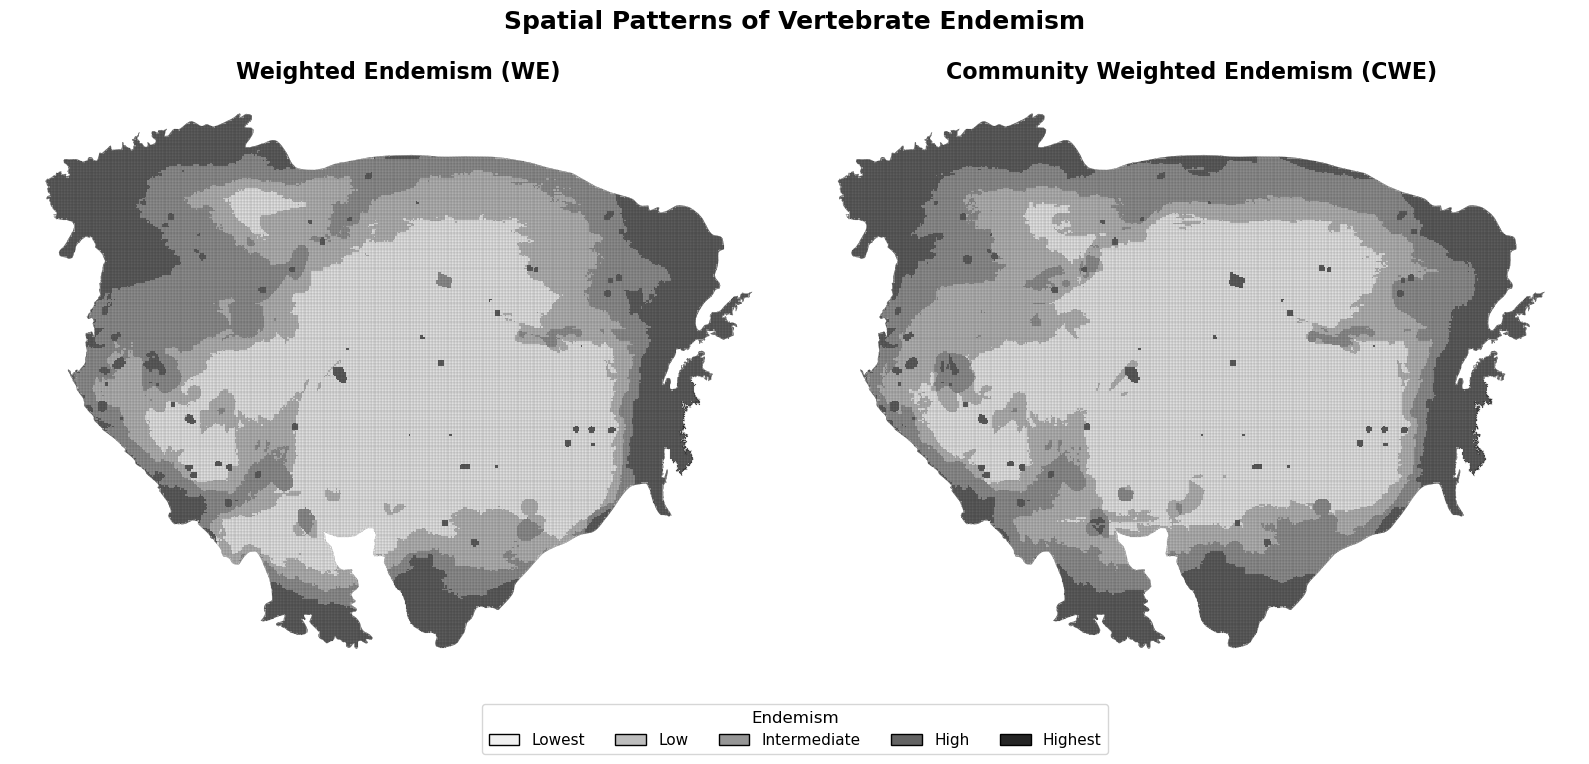

In [31]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# ---------------------------------------------------------
# 1. Define the five endemism categories
# ---------------------------------------------------------

labels = [
    "Lowest",
    "Low",
    "Intermediate",
    "High",
    "Highest"
]

# ---------------------------------------------------------
# 2. Classify WE and CWE using quintiles
# ---------------------------------------------------------

grid_overall_biodiversity["WE_class"] = pd.qcut(
    grid_overall_biodiversity["WE"],
    q=5,
    labels=labels,
    duplicates="drop"
)

grid_overall_biodiversity["CWE_class"] = pd.qcut(
    grid_overall_biodiversity["CWE"],
    q=5,
    labels=labels,
    duplicates="drop"
)

# ---------------------------------------------------------
# 3. Convert categories to numeric values
# ---------------------------------------------------------

class_values = {
    "Lowest": 1,
    "Low": 2,
    "Intermediate": 3,
    "High": 4,
    "Highest": 5
}

grid_overall_biodiversity["WE_class_num"] = grid_overall_biodiversity["WE_class"].map(class_values)
grid_overall_biodiversity["CWE_class_num"] = grid_overall_biodiversity["CWE_class"].map(class_values)

# ---------------------------------------------------------
# 4. Create figure
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 8)
)

# Five discrete colours
cmap = ListedColormap([
    "#f0f0f0",   # Lowest
    "#bdbdbd",   # Low
    "#969696",   # Intermediate
    "#636363",   # High
    "#252525"    # Highest
])

# ---------------------------------------------------------
# 5. Weighted Endemism
# ---------------------------------------------------------

grid_overall_biodiversity.plot(
    column="WE_class_num",
    cmap=cmap,
    linewidth=0.05,
    edgecolor="black",
    ax=axes[0],
    vmin=1,
    vmax=5
)

axes[0].set_title(
    "Weighted Endemism (WE)",
    fontsize=16,
    fontweight="bold"
)

axes[0].axis("off")

# ---------------------------------------------------------
# 6. Corrected / Community Weighted Endemism
# ---------------------------------------------------------

grid_overall_biodiversity.plot(
    column="CWE_class_num",
    cmap=cmap,
    linewidth=0.05,
    edgecolor="black",
    ax=axes[1],
    vmin=1,
    vmax=5
)

axes[1].set_title(
    "Community Weighted Endemism (CWE)",
    fontsize=16,
    fontweight="bold"
)

axes[1].axis("off")

# ---------------------------------------------------------
# 7. Common legend
# ---------------------------------------------------------

from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor=cmap(0), edgecolor="black", label="Lowest"),
    Patch(facecolor=cmap(1), edgecolor="black", label="Low"),
    Patch(facecolor=cmap(2), edgecolor="black", label="Intermediate"),
    Patch(facecolor=cmap(3), edgecolor="black", label="High"),
    Patch(facecolor=cmap(4), edgecolor="black", label="Highest")
]

fig.legend(
    handles=legend_elements,
    title="Endemism",
    loc="lower center",
    ncol=5,
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    bbox_to_anchor=(0.5, 0.02)
)

# ---------------------------------------------------------
# 8. Overall figure
# ---------------------------------------------------------

plt.suptitle(
    "Spatial Patterns of Vertebrate Endemism",
    fontsize=18,
    fontweight="bold",
    y=0.96
)

plt.tight_layout(rect=[0, 0.10, 1, 0.94])

# Save
plt.savefig(
    "overall_endemism_WE_CWE.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
